# Actividad didáctica 2-M3 · Simulación de colas en el Banco de Colombia

**Pregunta de negocio:** con 3 cajas disponibles, ¿conviene asignar *1 caja exclusiva para retiros y 2 para pagos*, o *2 para retiros y 1 para pagos*? ¿Hace falta un cajero adicional?

**Enfoque:** simulación de eventos discretos de un día de operación (480 min), replicada varias veces con semillas distintas. Cada cajero es una cola **M/M/1** independiente con fila propia (disciplina FIFO).

### Supuestos del modelo (documentados)
1. **Generación de cada cliente:** se sortea la acción (70 % retiro / 30 % pago), luego el tipo de usuario con la Tabla 2 y, con el tipo, el tiempo hasta su llegada (exponencial con la media de la Tabla 1, columna *llegada*) y su tiempo de servicio (exponencial con la media de la columna *servicio*). Es la lectura del laboratorio; leer la Tabla 1 como un flujo de llegadas independiente por tipo exigiría ≈ 12 cajeros y volvería inútil la Tabla 2.
2. **Asignación a cajas:** el cliente se une a la fila **más corta** entre los cajeros que atienden su tipo de operación (desempate: el que se libera antes). Se hace un análisis de sensibilidad con asignación **al azar** (cajeros M/M/1 estrictamente independientes).
3. El banco abre 480 min: las llegadas se aceptan hasta el minuto 480 y se atiende a todos los que ya llegaron.
4. Desplazamiento despreciable, sin abandonos, sin fallas de cajeros, el día inicia vacío.
5. **Números aleatorios comunes:** en cada réplica todos los escenarios reciben exactamente la misma secuencia de clientes. Así las diferencias entre escenarios se deben a la configuración y no al azar, y se pueden usar pruebas pareadas.

In [1]:
import math, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
os.makedirs('figuras', exist_ok=True)

# ---------------- Parámetros del enunciado (Tablas 1 y 2) ----------------
T = 480                                   # minutos de operación (8 h)
SEED_BASE = 2026                          # semilla base reproducible
TIPOS = ['Rápido', 'Normal', 'Lento', 'Muy lento']
P_ACCION  = {'Retiro': 0.70, 'Pago': 0.30}
P_TIPO    = {'Retiro': [.23, .40, .17, .20], 'Pago': [.10, .20, .30, .40]}
MEDIA_SERV = {'Retiro': [1, 2, 3, 4], 'Pago': [3, 3, 5, 7]}     # min
MEDIA_LLEG = {'Retiro': [1, 2, 3, 3], 'Pago': [1, 2, 3, 4]}     # min

# Validación de los datos de entrada
assert abs(sum(P_ACCION.values()) - 1) < 1e-9
assert all(abs(sum(p) - 1) < 1e-9 for p in P_TIPO.values())

# ---------------- Valores teóricos del modelo ----------------
gap  = {a: float(np.dot(P_TIPO[a], MEDIA_LLEG[a])) for a in P_ACCION}
serv = {a: float(np.dot(P_TIPO[a], MEDIA_SERV[a])) for a in P_ACCION}
gap_medio  = sum(P_ACCION[a] * gap[a]  for a in P_ACCION)
serv_medio = sum(P_ACCION[a] * serv[a] for a in P_ACCION)
lam = 1 / gap_medio                       # clientes/min
carga = {a: lam * P_ACCION[a] * serv[a] for a in P_ACCION}   # cajeros-equivalentes
print(f"Tiempo medio entre llegadas : {gap_medio:.3f} min  ->  λ = {lam:.3f} clientes/min  (≈ {T*lam:.0f} clientes/día)")
print(f"Servicio medio retiro/pago  : {serv['Retiro']:.2f} / {serv['Pago']:.2f} min  (global {serv_medio:.3f} min)")
print(f"Carga de trabajo            : retiros {carga['Retiro']:.2f} + pagos {carga['Pago']:.2f} = {sum(carga.values()):.2f} cajeros-equivalentes")
print(f"Utilización teórica con 3 cajas (ρ = λ·E[S]/c): {lam*serv_medio/3:.3f}  -> sistema estable (ρ < 1)")

Tiempo medio entre llegadas : 2.398 min  ->  λ = 0.417 clientes/min  (≈ 200 clientes/día)
Servicio medio retiro/pago  : 2.34 / 5.20 min  (global 3.198 min)
Carga de trabajo            : retiros 0.68 + pagos 0.65 = 1.33 cajeros-equivalentes
Utilización teórica con 3 cajas (ρ = λ·E[S]/c): 0.445  -> sistema estable (ρ < 1)


## 1. Modelo de simulación

In [2]:
def generar_dia(rng, horizonte=T):
    """Genera los clientes de un día: (acción, tipo, instante de llegada, tiempo de servicio)."""
    clientes, t = [], 0.0
    while True:
        accion = 'Retiro' if rng.random() < P_ACCION['Retiro'] else 'Pago'
        k = rng.choice(4, p=P_TIPO[accion])                 # tipo de usuario (Tabla 2)
        t += rng.exponential(MEDIA_LLEG[accion][k])         # llegada (Tabla 1)
        if t > horizonte:
            break
        s = rng.exponential(MEDIA_SERV[accion][k])          # servicio (Tabla 1)
        clientes.append((accion, k, t, s))
    return clientes


def simular(clientes, config, politica='corta', rng=None):
    """Cajeros M/M/1 en paralelo, cada uno con su fila FIFO.
    config  : lista de conjuntos con las operaciones que atiende cada cajero,
              p. ej. [{'Retiro','Pago'}]*3  (mixtas)  o  [{'Retiro'},{'Pago'},{'Pago'}].
    politica: 'corta' -> fila más corta entre cajeros elegibles; 'azar' -> cajero elegible al azar.
    Devuelve (DataFrame por cliente, utilización por cajero).
    """
    # n = número de cajeros; cada uno es una cola M/M/1 con su propia fila FIFO
    n = len(config)
    libre = np.zeros(n)                     # instante en que cada cajero queda libre
    ocupado = np.zeros(n)                   # minutos de servicio acumulados
    en_fila = [[] for _ in range(n)]        # fines de servicio de quienes están en el sistema de cada cajero
    reg = []
    for accion, k, t, s in clientes:
        # cajeros que pueden atender esta operación (en cajas exclusivas solo los de su tipo)
        elegibles = [i for i in range(n) if accion in config[i]]
        if politica == 'corta':
            for i in elegibles:             # sacar a quienes ya terminaron antes de t
                en_fila[i] = [f for f in en_fila[i] if f > t]
            # fila más corta; desempate: el cajero que se libera antes
            i = min(elegibles, key=lambda j: (len(en_fila[j]), libre[j]))
        else:
            # sensibilidad: el cliente elige al azar entre los cajeros elegibles
            i = int(rng.choice(elegibles))
        inicio = max(t, libre[i])           # recursión de Lindley: espera = max(0, libre - llegada)
        fin = inicio + s
        # actualizar el estado del cajero y registrar espera, servicio y tiempo en el sistema
        libre[i] = fin; ocupado[i] += s; en_fila[i].append(fin)
        reg.append((accion, TIPOS[k], i, t, inicio - t, s, fin - t))
    df = pd.DataFrame(reg, columns=['accion', 'tipo', 'cajero', 'llegada', 'espera', 'servicio', 'sistema'])
    cierre = max(T, libre.max())            # incluye el tiempo extra si queda gente al cerrar
    return df, ocupado / cierre


# ---------------- Escenarios ----------------
MIX = {'Retiro', 'Pago'}
ESC3 = {   # los 3 escenarios pedidos
    'E1: 3 mixtas':          [MIX, MIX, MIX],
    'E2: 1 retiro + 2 pagos':  [{'Retiro'}, {'Pago'}, {'Pago'}],
    'E3: 2 retiros + 1 pago':  [{'Retiro'}, {'Retiro'}, {'Pago'}],
}
ESC_EXTRA = {  # para evaluar la necesidad de un cajero adicional (punto 4)
    'E4: 4 mixtas':          [MIX, MIX, MIX, MIX],
    'E5: 2 retiros + 2 pagos': [{'Retiro'}, {'Retiro'}, {'Pago'}, {'Pago'}],
}
ESC_TODOS = {**ESC3, **ESC_EXTRA}

### 1.1 Verificación del simulador contra la teoría M/M/1
Antes de confiar en el modelo se comprueba que `simular` reproduce una cola M/M/1 conocida: λ = 1/2, μ = 1/1,2 (ρ = 0,6). La teoría da Wq = ρ/(μ−λ) = 1,8 min.

In [3]:
# Validación: una cola M/M/1 con solución analítica conocida (λ = 1/2, μ = 1/1,2, ρ = 0,6)
rng = np.random.default_rng(1)
n = 150_000                                          # muchos clientes para que la media converja
llegadas = np.cumsum(rng.exponential(2.0, n)); servicios = rng.exponential(1.2, n)
prueba = [('Retiro', 0, a, s) for a, s in zip(llegadas, servicios)]
df_v, _ = simular(prueba, [{'Retiro'}])
lam_v, mu_v = 1/2.0, 1/1.2
# Wq teórico M/M/1 = ρ / (μ − λ)
wq_teo = (lam_v/mu_v) / (mu_v - lam_v)
wq_sim = df_v['espera'].iloc[5000:].mean()          # se descarta el calentamiento
print(f"Wq teórico = {wq_teo:.3f} min | Wq simulado = {wq_sim:.3f} min | error relativo = {abs(wq_sim-wq_teo)/wq_teo:.1%}")

Wq teórico = 1.800 min | Wq simulado = 1.820 min | error relativo = 1.1%


## 2. Réplicas: cuántas se necesitan

In [4]:
def ejecutar(escenarios, n_rep, politica='corta'):
    """Corre n_rep días. Cada día usa la misma lista de clientes en todos los escenarios (números aleatorios comunes)."""
    detalle, utils, llegadas_dia = [], [], []
    for r in range(n_rep):
        clientes = generar_dia(np.random.default_rng(SEED_BASE + r))
        # Nota: rng_asig se consume de forma secuencial entre escenarios; por eso, con la política 'azar', los escenarios no comparten los mismos
        # sorteos de asignación y en la sensibilidad solo se reportan medias (no pruebas pareadas).
        rng_asig = np.random.default_rng(900_000 + SEED_BASE + r)       # solo se usa con política 'azar'
        llegadas_dia.append(pd.DataFrame([(r+1, a, TIPOS[k]) for a, k, _, _ in clientes], columns=['rep', 'accion', 'tipo']))
        for nombre, config in escenarios.items():
            df, util = simular(clientes, config, politica, rng_asig)
            df['escenario'] = nombre; df['rep'] = r + 1
            detalle.append(df)
            utils += [(nombre, r+1, c+1, u) for c, u in enumerate(util)]
    return (pd.concat(detalle, ignore_index=True),
            pd.DataFrame(utils, columns=['escenario', 'rep', 'cajero', 'util']),
            pd.concat(llegadas_dia, ignore_index=True))


def media_ic(x, conf=0.95):
    x = np.asarray(x, float); m = x.mean()
    h = stats.t.ppf(1 - (1 - conf) / 2, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan
    return m, h


def resumen_rep(det):
    """Métricas por (escenario, réplica)."""
    g = det.groupby(['escenario', 'rep'])
    r = g.agg(clientes=('espera', 'size'), Wq=('espera', 'mean'), W=('sistema', 'mean'),
              Wq_max=('espera', 'max'),
              pct_espera=('espera', lambda x: 100 * (x > 1e-9).mean()),
              pct_mayor5=('espera', lambda x: 100 * (x > 5).mean())).reset_index()
    a = det.groupby(['escenario', 'rep', 'accion']).espera.mean().unstack().reset_index()
    a.columns = ['escenario', 'rep', 'Wq_pago', 'Wq_retiro']
    return r.merge(a, on=['escenario', 'rep'])


# --- Piloto de 10 réplicas para dimensionar el número de réplicas ---
H = 1.0          # semiancho deseado del IC95 % de Wq (min); las diferencias entre escenarios son de ~2 min
det_p, _, _ = ejecutar(ESC3, 10)
rp = resumen_rep(det_p)
filas = []
for esc, sub in rp.groupby('escenario'):
    s = sub['Wq'].std(ddof=1)
    n_req = math.ceil((stats.t.ppf(0.975, 9) * s / H) ** 2)
    filas.append((esc, sub['Wq'].mean(), s, n_req))
piloto = pd.DataFrame(filas, columns=['Escenario', 'Wq piloto (min)', 'Desv. entre réplicas', f'Réplicas para ±{H} min'])
display(piloto.round(2))
N_REP = max(10, int(math.ceil(piloto.iloc[:, 3].max() / 5) * 5))
print(f"\n>>> Se usarán N_REP = {N_REP} réplicas (n = (t·s/h)² del peor escenario, redondeado a múltiplo de 5).")

,Escenario,Wq piloto (min),Desv. entre réplicas,Réplicas para ±1.0 min
0,E1: 3 mixtas,0.54,0.24,1
1,E2: 1 retiro + 2 pagos,3.77,1.72,16
2,E3: 2 retiros + 1 pago,3.08,2.63,36



>>> Se usarán N_REP = 40 réplicas (n = (t·s/h)² del peor escenario, redondeado a múltiplo de 5).


## 3. Ejecución final de los escenarios

In [5]:
# Corrida final: N_REP réplicas de los 5 escenarios, con la política de fila más corta
det, util, llegadas = ejecutar(ESC_TODOS, N_REP, 'corta')
res = resumen_rep(det)
# Sensibilidad: asignación al azar (cajeros M/M/1 estrictamente independientes)
det_a, util_a, _ = ejecutar(ESC_TODOS, N_REP, 'azar')
res_a = resumen_rep(det_a)
print(f"{N_REP} réplicas x {len(ESC_TODOS)} escenarios | {len(det):,} clientes simulados")

def tabla_escenarios(res, escenarios, cols):
    filas = []
    for esc in escenarios:
        sub = res[res.escenario == esc]; fila = {'Escenario': esc}
        for etq, c in cols.items():
            m, h = media_ic(sub[c]); fila[etq] = f"{m:.2f} ± {h:.2f}"
        filas.append(fila)
    return pd.DataFrame(filas).set_index('Escenario')

cols = {'Clientes/día': 'clientes', 'Wq global (min)': 'Wq', 'Wq retiros': 'Wq_retiro', 'Wq pagos': 'Wq_pago',
        'W sistema (min)': 'W', 'Espera máx. (min)': 'Wq_max'}
display(tabla_escenarios(res, ESC_TODOS, cols))

40 réplicas x 5 escenarios | 40,505 clientes simulados


,Clientes/día,Wq global (min),Wq retiros,Wq pagos,W sistema (min),Espera máx. (min)
Escenario,,,,,,
E1: 3 mixtas,202.53 ± 4.42,0.66 ± 0.10,0.67 ± 0.12,0.62 ± 0.12,3.94 ± 0.16,16.22 ± 2.76
E2: 1 retiro + 2 pagos,202.53 ± 4.42,4.85 ± 0.84,6.55 ± 1.17,0.83 ± 0.24,8.14 ± 0.88,27.30 ± 3.45
E3: 2 retiros + 1 pago,202.53 ± 4.42,3.61 ± 0.76,0.48 ± 0.10,10.67 ± 2.37,6.90 ± 0.80,42.72 ± 6.62
E4: 4 mixtas,202.53 ± 4.42,0.11 ± 0.03,0.12 ± 0.03,0.10 ± 0.03,3.40 ± 0.10,6.51 ± 2.16
E5: 2 retiros + 2 pagos,202.53 ± 4.42,0.59 ± 0.10,0.48 ± 0.10,0.83 ± 0.24,3.88 ± 0.15,15.28 ± 2.92


## 4. Punto 1 · Cajero con menor y mayor tiempo promedio de atención

In [6]:
# PUNTO 1 · Tiempo de atención por cajero (sin segregar usuarios); se resume cada réplica y luego se promedian las 40
def tabla_cajeros(esc):
    d = det[det.escenario == esc]
    u = util[util.escenario == esc]
    g = d.groupby(['rep', 'cajero']).agg(clientes=('servicio', 'size'), servicio=('servicio', 'mean'),
                                          espera=('espera', 'mean'), sistema=('sistema', 'mean')).reset_index()
    g['cajero'] += 1
    g = g.merge(u, on=['rep', 'cajero'])
    filas = []
    for c, sub in g.groupby('cajero'):
        m_s, h_s = media_ic(sub['servicio'])
        filas.append({'Cajero': c, 'Atiende': ' y '.join(sorted(x + 's' for x in ESC_TODOS[esc][c-1])),
                      'Clientes/día': sub['clientes'].mean(), 'T. servicio (min)': m_s, '± IC95': h_s,
                      'T. espera (min)': sub['espera'].mean(), 'T. en sistema (min)': sub['sistema'].mean(),
                      'Utilización': sub['util'].mean()})
    return pd.DataFrame(filas).set_index('Cajero'), g

for esc in ESC3:
    print(f"\n=== {esc} ===")
    t, g = tabla_cajeros(esc)
    display(t.round(2))
    print(f"   Menor tiempo de atención: cajero {t['T. servicio (min)'].idxmin()} ({t['T. servicio (min)'].min():.2f} min) | "
          f"Mayor: cajero {t['T. servicio (min)'].idxmax()} ({t['T. servicio (min)'].max():.2f} min)")
    if esc.startswith('E1'):
        # ANOVA de un factor: ¿difieren los tiempos medios de servicio entre los 3 cajeros de E1?
        f, p = stats.f_oneway(*[s['servicio'].values for _, s in g.groupby('cajero')])
        print(f"   ANOVA entre cajeros (E1): F = {f:.2f}, p = {p:.3f} -> "
              + ("diferencias significativas" if p < 0.05 else "NO hay evidencia de diferencias: por construcción son cajeros idénticos"))


=== E1: 3 mixtas ===


,Atiende,Clientes/día,T. servicio (min),± IC95,T. espera (min),T. en sistema (min),Utilización
Cajero,,,,,,,
1,Pagos y Retiros,65.75,3.47,0.17,0.70,4.16,0.46
2,Pagos y Retiros,68.42,3.25,0.16,0.66,3.91,0.45
3,Pagos y Retiros,68.35,3.23,0.15,0.64,3.87,0.45


   Menor tiempo de atención: cajero 3 (3.23 min) | Mayor: cajero 1 (3.47 min)
   ANOVA entre cajeros (E1): F = 2.71, p = 0.071 -> NO hay diferencias significativas: son cajeros idénticos y la diferencia es azar

=== E2: 1 retiro + 2 pagos ===


,Atiende,Clientes/día,T. servicio (min),± IC95,T. espera (min),T. en sistema (min),Utilización
Cajero,,,,,,,
1,Retiros,141.07,2.37,0.08,6.55,8.92,0.68
2,Pagos,31.02,5.34,0.35,0.84,6.18,0.33
3,Pagos,30.42,5.54,0.30,0.84,6.38,0.34


   Menor tiempo de atención: cajero 1 (2.37 min) | Mayor: cajero 3 (5.54 min)

=== E3: 2 retiros + 1 pago ===


,Atiende,Clientes/día,T. servicio (min),± IC95,T. espera (min),T. en sistema (min),Utilización
Cajero,,,,,,,
1,Retiros,70.20,2.41,0.13,0.47,2.89,0.34
2,Retiros,70.88,2.35,0.12,0.50,2.85,0.34
3,Pagos,61.45,5.39,0.20,10.67,16.06,0.67


   Menor tiempo de atención: cajero 2 (2.35 min) | Mayor: cajero 3 (5.39 min)


## 5. Puntos 2 y 3 · Usuarios por tipo

In [7]:
# PUNTOS 2 y 3 · Usuarios por tipo (los mismos en los 3 escenarios por los números aleatorios comunes)
llegadas['clave'] = llegadas['accion'] + ' · ' + llegadas['tipo']
orden = [f"{a} · {t}" for a in ['Retiro', 'Pago'] for t in TIPOS]
cuentas = llegadas.pivot_table(index='rep', columns='clave', values='tipo', aggfunc='size', fill_value=0)[orden]
cuentas['Total'] = cuentas.sum(axis=1)

# Valor esperado = (480 / tiempo medio entre llegadas) × P(acción) × P(tipo)
esperado = {f"{a} · {TIPOS[k]}": (T / gap_medio) * P_ACCION[a] * P_TIPO[a][k] for a in P_ACCION for k in range(4)}
esperado['Total'] = T / gap_medio
punto2 = pd.DataFrame({'Promedio por día': cuentas.mean(), 'Desv. estándar': cuentas.std(ddof=1),
                       'IC95 ±': [media_ic(cuentas[c])[1] for c in cuentas.columns],
                       'Esperado (teórico)': pd.Series(esperado)})
print("PUNTO 2 · Promedio de usuarios de cada tipo en la totalidad de cajeros (por día de 8 h)")
display(punto2.round(1))

print("\nPUNTO 3 · Total de usuarios de cada tipo en cada réplica")
display(cuentas)
print("Réplica con MENOR cantidad de usuarios por tipo:")
# idxmin devuelve la primera réplica en caso de empate
menor = pd.DataFrame({'Réplica': cuentas.idxmin(), 'Usuarios': cuentas.min()})
display(menor)
print(f"Réplica con menos usuarios en total: #{cuentas['Total'].idxmin()} ({cuentas['Total'].min()} clientes) | "
      f"con más: #{cuentas['Total'].idxmax()} ({cuentas['Total'].max()} clientes)")
print("Nota: por los números aleatorios comunes, los tres escenarios reciben exactamente los mismos clientes en cada réplica.")

PUNTO 2 · Promedio de usuarios de cada tipo en la totalidad de cajeros (por día de 8 h)


,Promedio por día,Desv. estándar,IC95 ±,Esperado (teórico)
Retiro · Rápido,33.4,6.0,1.9,32.2
Retiro · Normal,54.5,6.7,2.1,56.0
Retiro · Lento,24.4,5.0,1.6,23.8
Retiro · Muy lento,28.8,5.1,1.6,28.0
Pago · Rápido,6.6,2.0,0.6,6.0
Pago · Normal,12.4,3.7,1.2,12.0
Pago · Lento,18.4,4.8,1.5,18.0
Pago · Muy lento,24.1,4.0,1.3,24.0
Total,202.5,13.8,4.4,200.2



PUNTO 3 · Total de usuarios de cada tipo en cada réplica


clave,Retiro · Rápido,Retiro · Normal,Retiro · Lento,Retiro · Muy lento,Pago · Rápido,Pago · Normal,Pago · Lento,Pago · Muy lento,Total
rep,,,,,,,,,
1,30,50,20,32,7,11,14,26,190
2,37,42,16,32,7,10,13,22,179
3,33,60,25,23,8,11,22,31,213
4,36,57,25,27,7,6,25,28,211
5,22,61,27,21,4,7,13,25,180
6,42,54,31,34,11,15,18,20,225
7,29,63,25,35,8,7,14,14,195
8,24,47,21,24,9,9,12,22,168
9,36,51,26,22,10,18,26,23,212


Réplica con MENOR cantidad de usuarios por tipo:


,Réplica,Usuarios
clave,,
Retiro · Rápido,5,22
Retiro · Normal,2,42
Retiro · Lento,37,15
Retiro · Muy lento,18,20
Pago · Rápido,22,3
Pago · Normal,4,6
Pago · Lento,19,9
Pago · Muy lento,7,14
Total,8,168


Réplica con menos usuarios en total: #8 (168 clientes) | con más: #6 (225 clientes)
Nota: por los números aleatorios comunes, los tres escenarios reciben exactamente los mismos clientes en cada réplica.


## 6. Punto 4 · ¿Es necesario un cajero adicional?

In [8]:
# PUNTO 4 · ¿Se necesita un cuarto cajero? Se compara E1, E4 y E5 contra el criterio de servicio
UMBRAL_WQ = 2.0     # espera media aceptable (min)  -> criterio del analista, editable
UMBRAL_P5 = 0.10    # fracción máxima de clientes que esperan más de 5 min

# Un escenario 'cumple' si Wq ≤ UMBRAL_WQ y a lo sumo UMBRAL_P5 de los clientes espera más de 5 min
def criterio(res_, util_):
    comp = {}
    for esc in ['E1: 3 mixtas', 'E4: 4 mixtas', 'E2: 1 retiro + 2 pagos', 'E3: 2 retiros + 1 pago', 'E5: 2 retiros + 2 pagos']:
        sub = res_[res_.escenario == esc]
        ut = util_[util_.escenario == esc].groupby('rep').util.mean()
        comp[esc] = {'Wq (min)': sub.Wq.mean(), '± IC95': media_ic(sub.Wq)[1], '% espera > 0': sub.pct_espera.mean(),
                     '% espera > 5 min': sub.pct_mayor5.mean(), 'Utilización media': ut.mean(),
                     'Cumple criterio': bool(sub.Wq.mean() <= UMBRAL_WQ and sub.pct_mayor5.mean() <= 100 * UMBRAL_P5)}
    return pd.DataFrame(comp).T

print("Política principal (fila más corta):")
punto4 = criterio(res, util)
display(punto4)
print("Sensibilidad (asignación al azar):")
display(criterio(res_a, util_a))

# Prueba t pareada: E1 y E4 usan los mismos clientes en cada réplica
a = res[res.escenario == 'E1: 3 mixtas'].set_index('rep').Wq
b = res[res.escenario == 'E4: 4 mixtas'].set_index('rep').Wq
t_, p_ = stats.ttest_rel(a, b)
print(f"Reducción de espera al pasar de 3 a 4 cajas mixtas: {a.mean()-b.mean():.2f} min (prueba t pareada p = {p_:.4f})")
print(f"Criterio: Wq ≤ {UMBRAL_WQ} min y ≤ {UMBRAL_P5:.0%} de clientes con espera > 5 min.")

Política principal (fila más corta):


,Wq (min),± IC95,% espera > 0,% espera > 5 min,Utilización media,Cumple criterio
E1: 3 mixtas,0.657791,0.102162,21.233922,3.964422,0.454904,True
E4: 4 mixtas,0.113078,0.028887,6.756813,0.461663,0.341431,True
E2: 1 retiro + 2 pagos,4.852945,0.839735,55.071944,30.771365,0.451209,False
E3: 2 retiros + 1 pago,3.614089,0.755322,33.857885,16.294883,0.448031,False
E5: 2 retiros + 2 pagos,0.591998,0.095205,19.198042,3.547989,0.341064,True


Sensibilidad (asignación al azar):


,Wq (min),± IC95,% espera > 0,% espera > 5 min,Utilización media,Cumple criterio
E1: 3 mixtas,3.854348,0.365564,46.79966,23.764882,0.450196,False
E4: 4 mixtas,2.431957,0.242404,35.757192,16.118775,0.338572,False
E2: 1 retiro + 2 pagos,5.455305,0.84421,59.983992,34.471016,0.449682,False
E3: 2 retiros + 1 pago,4.412416,0.769692,46.114981,22.579268,0.447478,False
E5: 2 retiros + 2 pagos,2.036951,0.237124,36.141718,13.810434,0.3396,False


Reducción de espera al pasar de 3 a 4 cajas mixtas: 0.54 min (prueba t pareada p = 0.0000)
Criterio: Wq ≤ 2.0 min y ≤ 10% de clientes con espera > 5 min.


## 7. Punto 5 · Configuración con cajas exclusivas

In [9]:
print("Escenarios 2 y 3 (cajas exclusivas) con E1 como referencia\n")
display(tabla_escenarios(res, ESC3, {'Wq global': 'Wq', 'Wq retiros': 'Wq_retiro', 'Wq pagos': 'Wq_pago',
                                     'W sistema': 'W', '% espera>5 min': 'pct_mayor5'}))
e2 = res[res.escenario == 'E2: 1 retiro + 2 pagos'].set_index('rep')
e3 = res[res.escenario == 'E3: 2 retiros + 1 pago'].set_index('rep')
# diferencia pareada por réplica (mismos clientes en ambos escenarios)
dif = e2.Wq - e3.Wq
t_, p_ = stats.ttest_rel(e2.Wq, e3.Wq)
print(f"\nWq(E2) − Wq(E3) = {dif.mean():.2f} ± {media_ic(dif)[1]:.2f} min (t pareada: p = {p_:.4g})")
mejor = 'E3: 2 retiros + 1 pago' if dif.mean() > 0 else 'E2: 1 retiro + 2 pagos'
print(f"Mejor espera global entre las dos configuraciones exclusivas: {mejor}")
print(f"Gana E3 en {int((e3.Wq < e2.Wq).sum())} de {N_REP} réplicas.")
print("\nCliente más perjudicado en cada configuración:")
for esc, e in [('E2', e2), ('E3', e3)]:
    print(f"  {esc}: retiros {e.Wq_retiro.mean():.2f} min | pagos {e.Wq_pago.mean():.2f} min")

# --- Sensibilidad: cajeros M/M/1 estrictamente independientes (asignación al azar) ---
print("\nSENSIBILIDAD · cliente elige cajero elegible al azar:")
display(tabla_escenarios(res_a, ESC_TODOS, {'Wq global': 'Wq', 'Wq retiros': 'Wq_retiro', 'Wq pagos': 'Wq_pago', '% espera>5 min': 'pct_mayor5'}))

Escenarios 2 y 3 (cajas exclusivas) con E1 como referencia



,Wq global,Wq retiros,Wq pagos,W sistema,% espera>5 min
Escenario,,,,,
E1: 3 mixtas,0.66 ± 0.10,0.67 ± 0.12,0.62 ± 0.12,3.94 ± 0.16,3.96 ± 0.72
E2: 1 retiro + 2 pagos,4.85 ± 0.84,6.55 ± 1.17,0.83 ± 0.24,8.14 ± 0.88,30.77 ± 3.86
E3: 2 retiros + 1 pago,3.61 ± 0.76,0.48 ± 0.10,10.67 ± 2.37,6.90 ± 0.80,16.29 ± 1.78



Wq(E2) − Wq(E3) = 1.24 ± 1.10 min (t pareada: p = 0.02789)
Mejor espera global entre las dos configuraciones exclusivas: E3: 2 retiros + 1 pago
Gana E3 en 28 de 40 réplicas.

Cliente más perjudicado en cada configuración:
  E2: retiros 6.55 min | pagos 0.83 min
  E3: retiros 0.48 min | pagos 10.67 min

SENSIBILIDAD · cliente elige cajero elegible al azar:


,Wq global,Wq retiros,Wq pagos,% espera>5 min
Escenario,,,,
E1: 3 mixtas,3.85 ± 0.37,3.95 ± 0.37,3.62 ± 0.43,23.76 ± 1.76
E2: 1 retiro + 2 pagos,5.46 ± 0.84,6.55 ± 1.17,2.80 ± 0.52,34.47 ± 3.92
E3: 2 retiros + 1 pago,4.41 ± 0.77,1.62 ± 0.24,10.67 ± 2.37,22.58 ± 1.94
E4: 4 mixtas,2.43 ± 0.24,2.45 ± 0.22,2.41 ± 0.39,16.12 ± 1.43
E5: 2 retiros + 2 pagos,2.04 ± 0.24,1.63 ± 0.25,2.94 ± 0.51,13.81 ± 1.51


### 7.1 Verificaciones complementarias
Pruebas y empates que se citan en el informe (Punto 1, Punto 3 y Punto 4).

In [ ]:
# Verificaciones complementarias citadas en el informe
# (a) Kruskal-Wallis entre los 3 cajeros de E1 (alternativa no paramétrica al ANOVA)
_, g1 = tabla_cajeros('E1: 3 mixtas')
h, p_kw = stats.kruskal(*[s['servicio'].values for _, s in g1.groupby('cajero')])
print(f"Kruskal-Wallis (E1): H = {h:.2f}, p = {p_kw:.3f}")

# (b) ¿Cambiar de 3 mixtas (E1) a 2 retiros + 2 pagos (E5) reduce la espera? (t pareada, mismos clientes)
e1 = res[res.escenario == 'E1: 3 mixtas'].set_index('rep').Wq
e5 = res[res.escenario == 'E5: 2 retiros + 2 pagos'].set_index('rep').Wq
_, p5 = stats.ttest_rel(e1, e5)
print(f"Wq(E1) − Wq(E5) = {(e1 - e5).mean():.2f} min; t pareada p = {p5:.3f}")

# (c) empates en el mínimo de usuarios por tipo (idxmin devuelve solo la primera réplica)
for c in cuentas.columns[:-1]:
    reps = list(cuentas.index[cuentas[c] == cuentas[c].min()])
    if len(reps) > 1:
        print(f"Empate en {c}: mínimo {cuentas[c].min()} en las réplicas {reps}")


Kruskal-Wallis (E1): H = 4.38, p = 0.112
Wq(E1) − Wq(E5) = 0.07 min; t pareada p = 0.157
Empate en Retiro · Normal: mínimo 42 en las réplicas [2, 35]
Empate en Pago · Normal: mínimo 6 en las réplicas [4, 10]


## 8. Gráficas

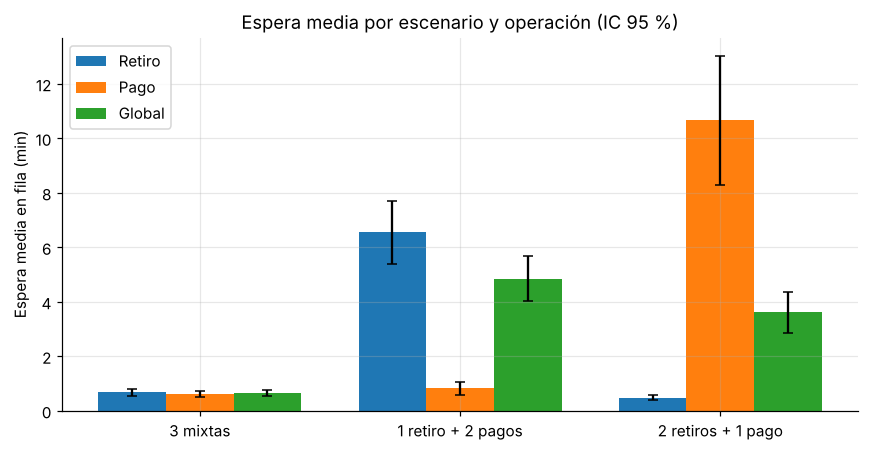

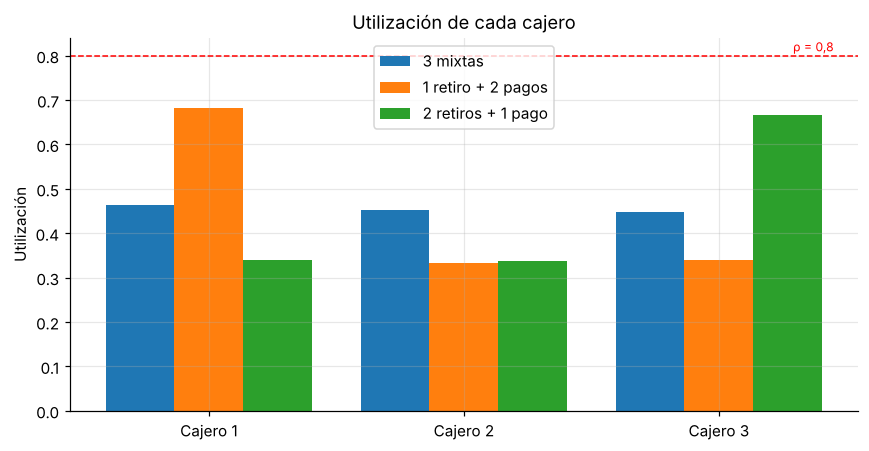

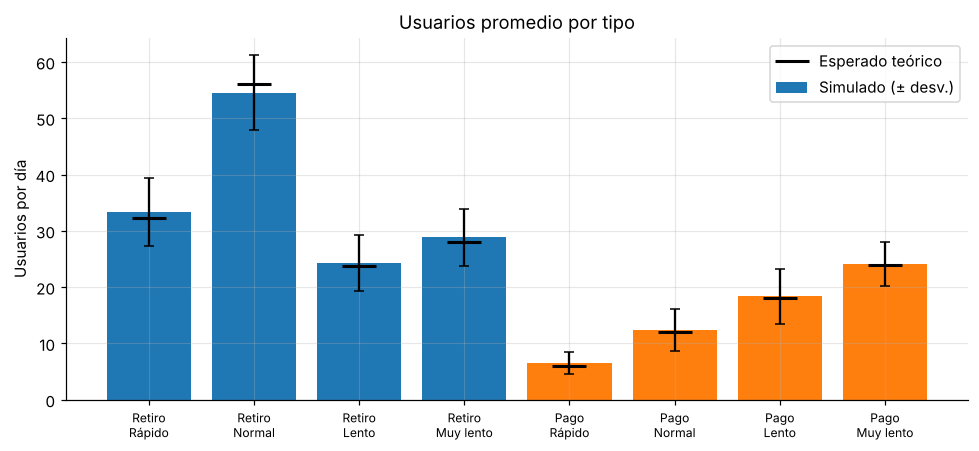

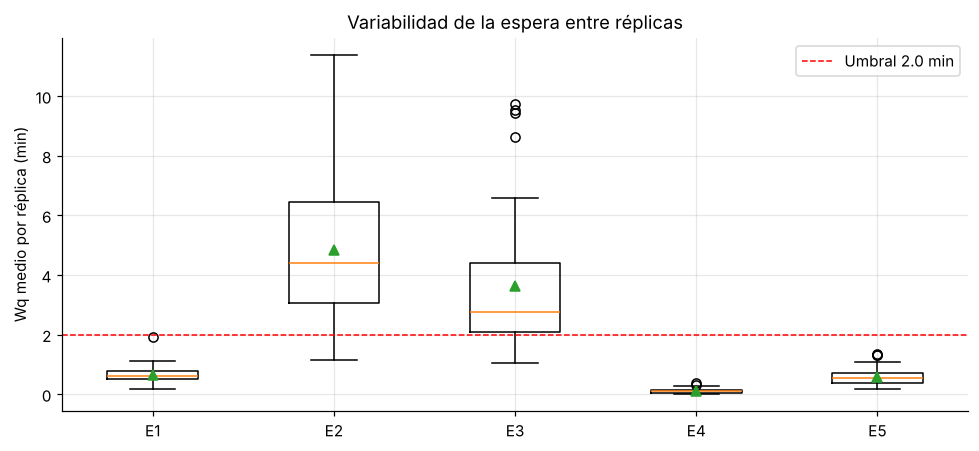

In [10]:
col = {'Retiro': '#1f77b4', 'Pago': '#ff7f0e', 'Global': '#2ca02c'}
# Figura 1 del informe: espera por escenario y tipo de operación
fig, ax = plt.subplots(figsize=(8, 4.2))
esc3 = list(ESC3); x = np.arange(len(esc3)); w = .26
for j, (c, nombre) in enumerate([('Wq_retiro', 'Retiro'), ('Wq_pago', 'Pago'), ('Wq', 'Global')]):
    m = [media_ic(res[res.escenario == e][c])[0] for e in esc3]; h = [media_ic(res[res.escenario == e][c])[1] for e in esc3]
    ax.bar(x + (j - 1) * w, m, w, yerr=h, capsize=3, label=nombre, color=col[nombre])
ax.set_xticks(x); ax.set_xticklabels([e.split(': ')[1] for e in esc3]); ax.set_ylabel('Espera media en fila (min)')
ax.set_title('Espera media por escenario y operación (IC 95 %)'); ax.legend(); fig.tight_layout(); fig.savefig('figuras/fig1_espera_escenarios.png'); plt.show()

# Figura 4 del informe: utilización por cajero
fig, ax = plt.subplots(figsize=(8, 4.2))
for i, e in enumerate(esc3):
    u = util[util.escenario == e].groupby('cajero').util.mean()
    ax.bar(np.arange(len(u)) + i * 0.27 - 0.27, u.values, 0.27, label=e.split(': ')[1])
ax.axhline(0.8, ls='--', c='r', lw=1); ax.text(2.45, 0.81, 'ρ = 0,8', color='r', fontsize=8, ha='right')
ax.set_xticks(range(3)); ax.set_xticklabels(['Cajero 1', 'Cajero 2', 'Cajero 3']); ax.set_ylabel('Utilización')
ax.set_title('Utilización de cada cajero'); ax.legend(); fig.tight_layout(); fig.savefig('figuras/fig4_utilizacion.png'); plt.show()

# Figura 2 del informe: usuarios por tipo
fig, ax = plt.subplots(figsize=(9, 4.2))
ordx = orden; m = cuentas[ordx].mean(); s = cuentas[ordx].std(ddof=1)
ax.bar(range(8), m, yerr=s, capsize=3, color=['#1f77b4'] * 4 + ['#ff7f0e'] * 4, label='Simulado (± desv.)')
ax.plot(range(8), [esperado[k] for k in ordx], 'k_', ms=22, mew=2, label='Esperado teórico')
ax.set_xticks(range(8)); ax.set_xticklabels([o.replace(' · ', '\n') for o in ordx], fontsize=8)
ax.set_ylabel('Usuarios por día'); ax.set_title('Usuarios promedio por tipo'); ax.legend(); fig.tight_layout(); fig.savefig('figuras/fig2_usuarios_tipo.png'); plt.show()

# Figura 3 del informe: variabilidad entre réplicas
fig, ax = plt.subplots(figsize=(9, 4.2))
orden_e = list(ESC_TODOS)
ax.boxplot([res[res.escenario == e].Wq for e in orden_e], showmeans=True)
ax.set_xticklabels([e.split(': ')[0] for e in orden_e])
ax.axhline(UMBRAL_WQ, ls='--', c='r', lw=1, label=f'Umbral {UMBRAL_WQ} min'); ax.legend()
ax.set_ylabel('Wq medio por réplica (min)'); ax.set_title('Variabilidad de la espera entre réplicas')
fig.tight_layout(); fig.savefig('figuras/fig3_boxplot_replicas.png'); plt.show()

## 9. Exportar evidencias

In [11]:
# Exportar las evidencias: una hoja por tabla (el Excel se adjunta a la entrega)
with pd.ExcelWriter('resultados_simulacion_banco.xlsx') as xw:
    res.round(3).to_excel(xw, sheet_name='Resumen_por_replica', index=False)
    cuentas.to_excel(xw, sheet_name='Usuarios_por_replica')
    punto2.round(2).to_excel(xw, sheet_name='Usuarios_promedio')
    util.round(4).to_excel(xw, sheet_name='Utilizacion', index=False)
    punto4.to_excel(xw, sheet_name='Nuevo_cajero')
    det[det.escenario == 'E1: 3 mixtas'].round(3).to_excel(xw, sheet_name='Detalle_E1', index=False)
print('Archivo generado: resultados_simulacion_banco.xlsx | figuras/*.png')

Archivo generado: resultados_simulacion_banco.xlsx | figuras/*.png


## 10. Conclusiones (40 réplicas, semillas 2026–2065, fila más corta)

| Punto | Resultado |
|---|---|
| **1. Cajero con menor / mayor tiempo de atención** | Con 3 cajas mixtas: menor el cajero 3 (3,23 min) y mayor el cajero 1 (3,47 min), pero la diferencia **no es significativa** (ANOVA p = 0,071): por construcción son cajeros idénticos y no hay evidencia de una diferencia real. Con cajas exclusivas la diferencia sí es real: retiros ≈ 2,35–2,41 min frente a pagos ≈ 5,34–5,54 min. |
| **2. Promedio de usuarios por tipo** | 202,5 clientes/día (teórico 200,2). Retiros: rápido 33,4 · normal 54,5 · lento 24,4 · muy lento 28,8. Pagos: rápido 6,6 · normal 12,4 · lento 18,4 · muy lento 24,1. |
| **3. Usuarios por réplica** | Se necesitaron **40 réplicas** (piloto de 10 + n = (t·s/h)², h = 1 min). La réplica con menos clientes es la **#8 (168)** y la de más la #6 (225). Las tablas completas están en el Excel. |
| **4. ¿Nuevo cajero?** | **No es necesario** con 3 cajas mixtas: Wq = 0,66 min, solo 4 % de clientes espera más de 5 min y ρ ≈ 0,45. Una cuarta caja reduce la espera 0,54 min (a 0,11) con cajeros al 34 %: mejora real pero sin justificar el costo. |
| **5. Cajas exclusivas** | Entre las dos configuraciones exclusivas conviene **2 cajas de retiros + 1 de pagos**: Wq 3,61 vs 4,85 min (diferencia 1,24 ± 1,10 min, p = 0,028; gana en 28 de 40 réplicas) y 16 % vs 31 % de clientes esperando más de 5 min. |

**Por qué E3 supera a E2:** en ambos casos hay una caja “cuello de botella” con ρ ≈ 0,68. En E2 esa caja atiende retiros (70 % de los clientes, 6,55 min de espera); en E3 atiende pagos (30 % de los clientes, aunque con 10,67 min de espera). Perjudica a menos personas.

**Decisión final.** Si el banco debe especializar, que sean **2 cajas para retiros y 1 para pagos**. Pero la mejor de las tres configuraciones es mantener **3 cajas mixtas** (Wq 0,66 min frente a 3,61 y 4,85): al compartir la demanda se aprovecha mejor la capacidad (efecto de agrupamiento de recursos). Si se especializa, conviene sumar un cuarto cajero (2 retiros + 2 pagos: Wq 0,59 min), que logra lo mismo que 3 mixtas (0,66 min; diferencia no significativa, p = 0,157) pero sin ventaja adicional. Aun con E3, los clientes de pagos esperan 10,67 min en promedio.

**Sensibilidad y limitaciones.** Si los clientes eligieran cajero al azar (M/M/1 estrictamente independientes), todo empeora (3 mixtas: 3,85 min) y el ranking entre E2 y E3 se mantiene (5,46 vs 4,41), pero entonces sí se justificaría una cuarta caja (E5: 2,04 min). Los resultados dependen de la lectura de la Tabla 1 (supuesto 1), del umbral de servicio (Wq ≤ 2 min) y de que el día se parezca al día típico simulado (sin horas pico).